## 在deepseek api平台申请API，拿到API-key；然后交一点钱，很便宜的。

In [ ]:
# https://platform.deepseek.com/transactions

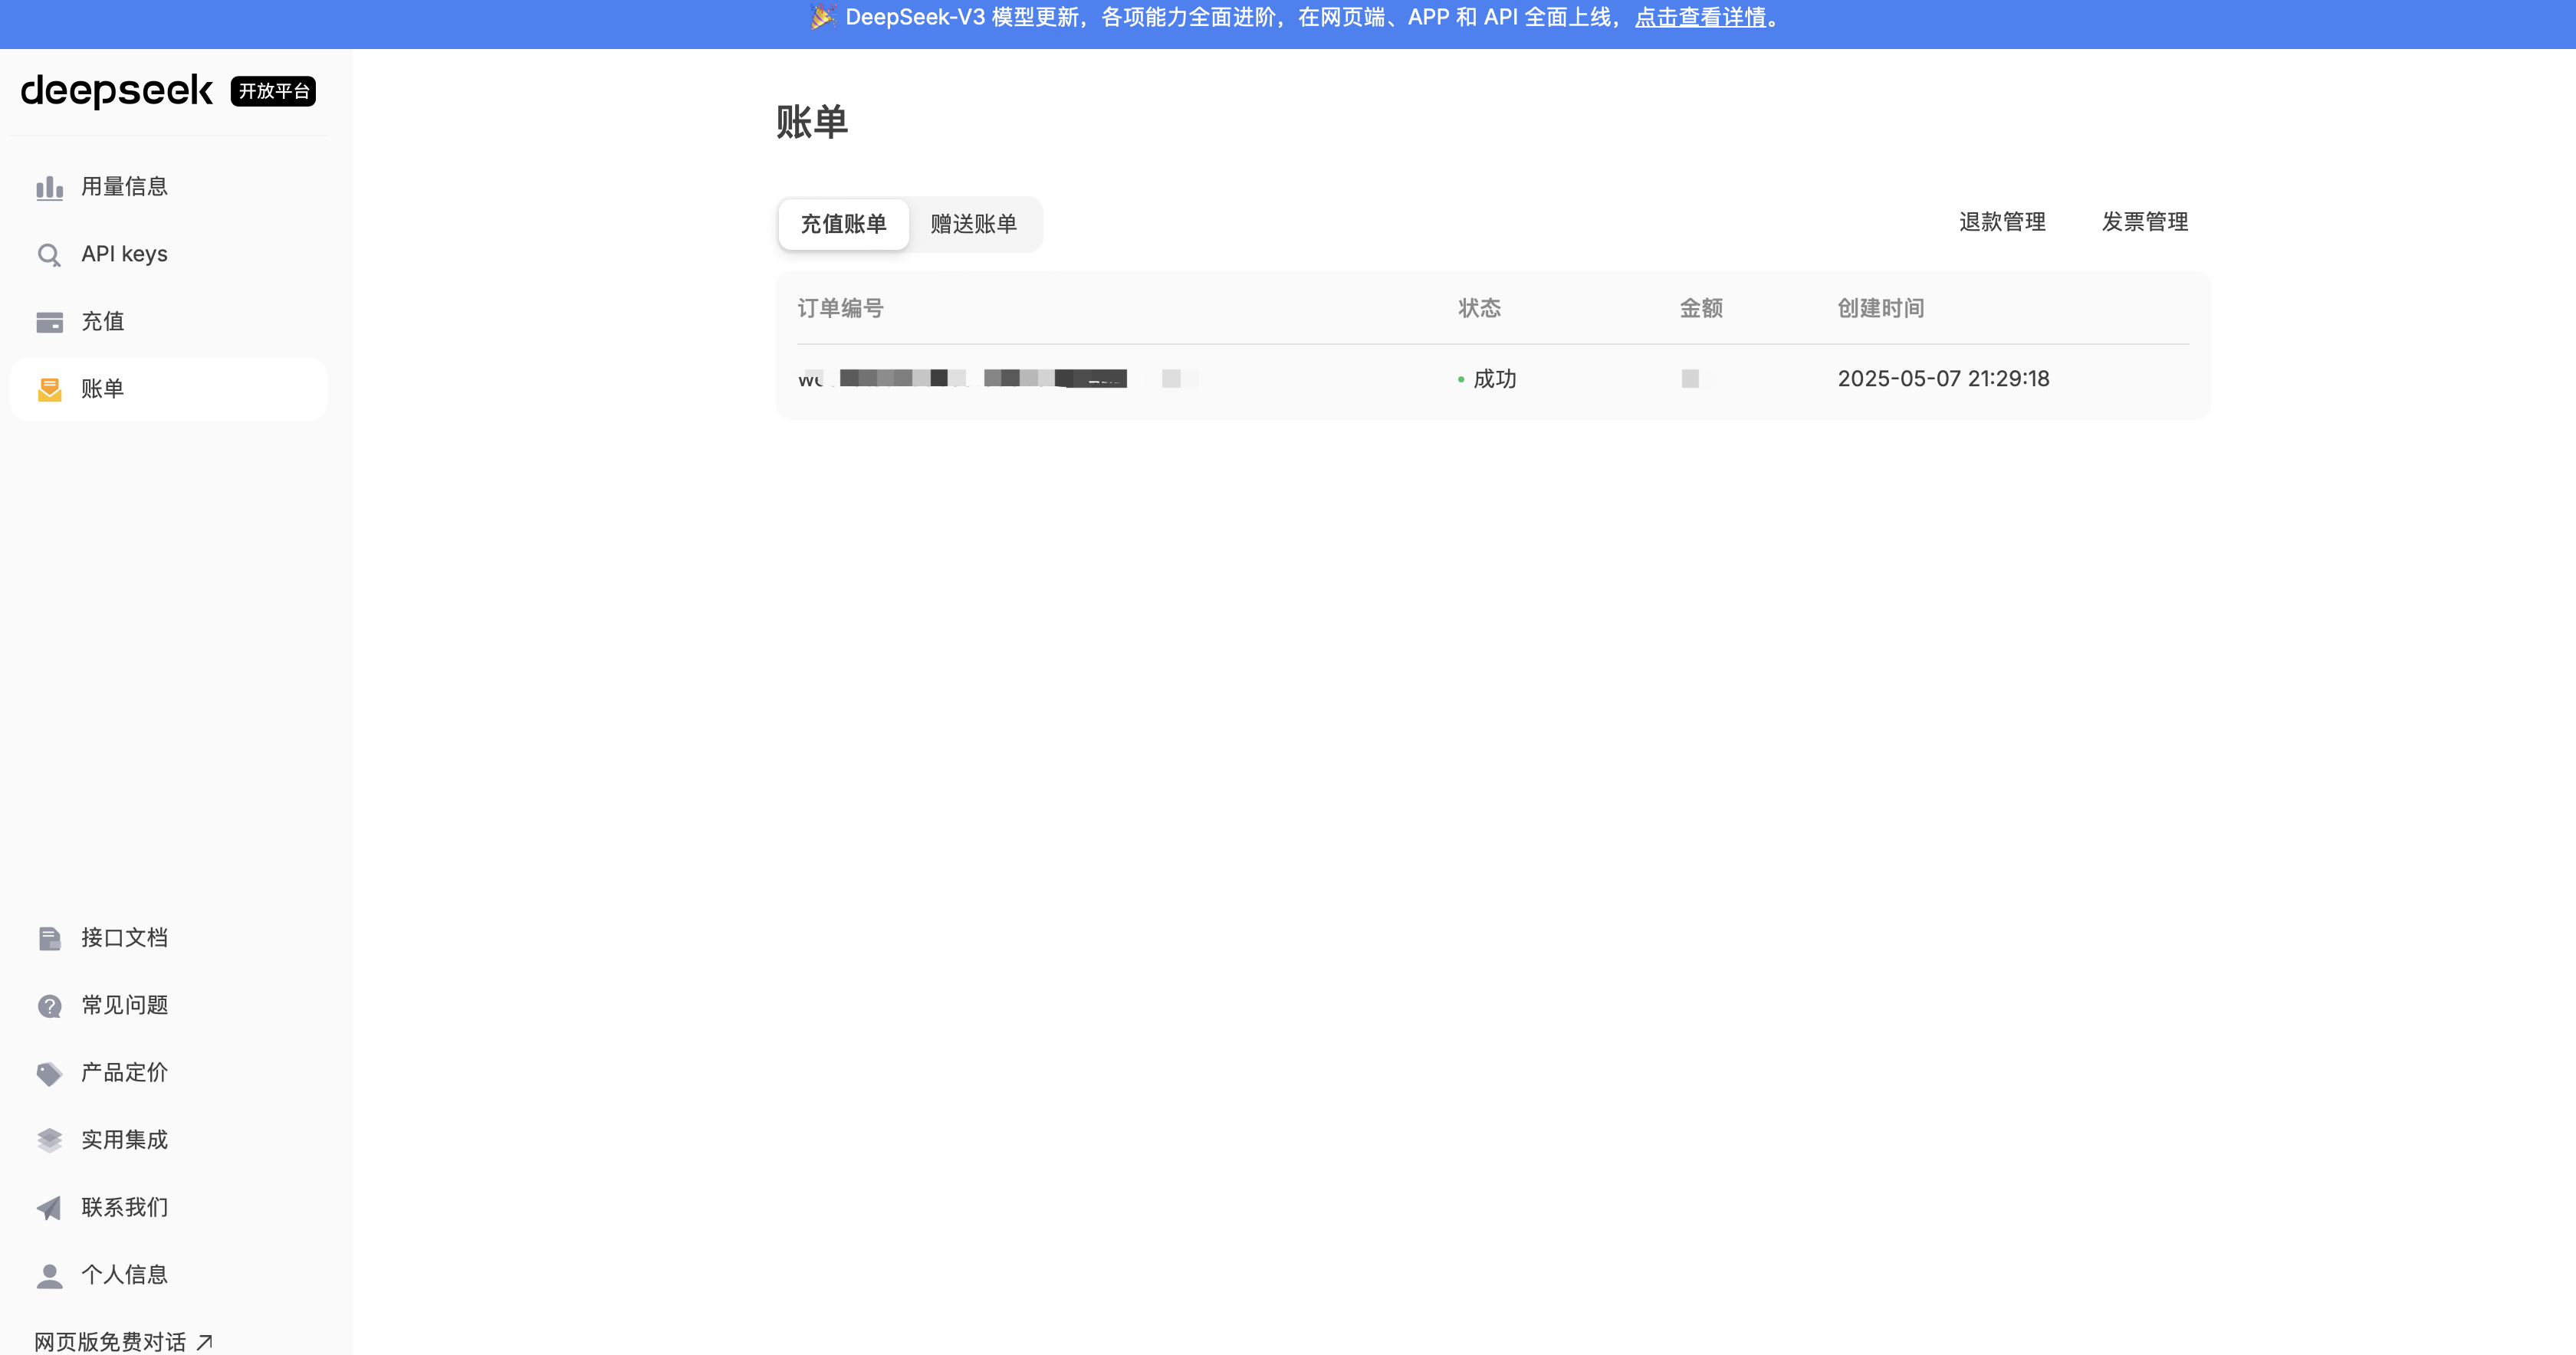

### 文学作品的情感轨迹
+ 步骤是这样的：
+ 1）读取txt文本，按照句号、感叹号，对文本进行分句，并且对句子进行编号；
+ 2）使用大语言模型，提取以上编号句子，每句话中的情感词，或者隐含的情感实体；
+ 3）用大语言模型计算出，每一个情感词或者情感词所在句子的情感得分；
+ 4）然后绘制一个时间序列的可视化图，横坐标是句子的序号，纵坐标是情感得分，每一个散点是句子对应的情感词，情感词作为散点的标签，然后用虚线把这些情感词连起来。

In [3]:
import re

with open("背影.txt", "r", encoding="utf-8") as f:
    text = f.read()

# 按照句号、感叹号进行分句（保留标点）
sentences = re.split(r'(?<=[。！])', text)
sentences = [s.strip() for s in sentences if s.strip()]
numbered_sentences = [(i + 1, s) for i, s in enumerate(sentences)]
#numbered_sentences = numbered_sentences[0:5] #大模型抽取很慢，提取文本的前n条句子

for num, sent in numbered_sentences:
    print(f"{num}: {sent}")


1: 我与父亲不相见已二年余了，我最不能忘记的是他的背影。
2: 那年冬天，祖母死了，父亲的差使也交卸了，正是祸不单行的日子。
3: 我从北京到徐州，打算跟着父亲奔丧回家。
4: 到徐州见着父亲，看见满院狼藉的东西，又想起祖母，不禁簌簌地流下眼泪。
5: 父亲说：“事已如此，不必难过，好在天无绝人之路！
6: ”
回家变卖典质，父亲还了亏空；又借钱办了丧事。
7: 这些日子，家中光景很是惨澹，一半为了丧事，一半为了父亲赋闲。
8: 丧事完毕，父亲要到南京谋事，我也要回北京念书，我们便同行。
9: 到南京时，有朋友约去游逛，勾留了一日；第二日上午便须渡江到浦口，下午上车北去。
10: 父亲因为事忙，本已说定不送我，叫旅馆里一个熟识的茶房陪我同去。
11: 他再三嘱咐茶房，甚是仔细。
12: 但他终于不放心，怕茶房不妥帖；颇踌躇了一会。
13: 其实我那年已二十岁，北京已来往过两三次，是没有什么要紧的了。
14: 他踌躇了一会，终于决定还是自己送我去。
15: 我再三劝他不必去；他只说：“不要紧，他们去不好！
16: ”
我们过了江，进了车站。
17: 我买票，他忙着照看行李。
18: 行李太多了，得向脚夫⑾行些小费才可过去。
19: 他便又忙着和他们讲价钱。
20: 我那时真是聪明过分，总觉他说话不大漂亮，非自己插嘴不可，但他终于讲定了价钱；就送我上车。
21: 他给我拣定了靠车门的一张椅子；我将他给我做的紫毛大衣铺好座位。
22: 他嘱我路上小心，夜里要警醒些，不要受凉。
23: 又嘱托茶房好好照应我。
24: 我心里暗笑他的迂；他们只认得钱，托他们只是白托！
25: 而且我这样大年纪的人，难道还不能料理自己么？我现在想想，我那时真是太聪明了。
26: 我说道：“爸爸，你走吧。
27: ”他往车外看了看，说：“我买几个橘子去。
28: 你就在此地，不要走动。
29: ”我看那边月台的栅栏外有几个卖东西的等着顾客。
30: 走到那边月台，须穿过铁道，须跳下去又爬上去。
31: 父亲是一个胖子，走过去自然要费事些。
32: 我本来要去的，他不肯，只好让他去。
33: 我看见他戴着黑布小帽，穿着黑布大马褂，深青布棉袍，蹒跚⒀地走到铁道边，慢慢探身下去，尚不大难。
34: 可是他穿过铁道，要爬上那边月台，就不容易了。
35: 他用两手攀着上面，两脚再向上缩；他肥胖的身子向左

In [4]:
import requests
import time
import re

API_KEY = "your key" #替换成你自己的密钥
API_URL = "https://api.deepseek.com/v1/chat/completions"

headers = {
    "Content-Type": "application/json",
    "Authorization": f"Bearer {API_KEY}"
}

emotion_results = []

for num, sent in numbered_sentences:
    prompt = f"""你是一个情感分析助手。请对下面这句话做如下分析：

1. 提取或生成一个最能代表情绪的词语（只能一个）；
2. 对整句话的情绪进行打分，范围是 -1（非常负面）到 1（非常正面），中性为 0。

直接用如下格式输出：
情感词：XXX
情感值：X.X

句子：{sent}"""

    data = {
        "model": "deepseek-chat",
        "messages": [{"role": "user", "content": prompt}],
        "temperature": 0.3
    }

    try:
        response = requests.post(API_URL, headers=headers, json=data)
        time.sleep(0.1)  # 控制请求频率

        if response.status_code == 200:
            content = response.json()['choices'][0]['message']['content']
            
            # 宽容匹配格式，如：情感词：悲伤、情感值：-0.6
            match = re.search(r"情感词[:：]?\s*([^\n\r：:\s]+)\s*[\n\r]+情感值[:：]?\s*(-?\d+(?:\.\d+)?)", content)
            if match:
                word = match.group(1)
                score = float(match.group(2))
                emotion_results.append((num, sent, word, score))
            else:
                print(f"[⚠️ 无法匹配] 第{num}句：{sent}")
                print("模型输出：", content)
                emotion_results.append((num, sent, "无", 0.0))
        else:
            print(f"[❌ API错误 {response.status_code}]")
            print(response.text)
            emotion_results.append((num, sent, "无", 0.0))

    except Exception as e:
        print(f"[异常] 第{num}句处理失败：{e}")
        emotion_results.append((num, sent, "无", 0.0))


In [5]:
for item in emotion_results:
    print(f"句子{item[0]}：情感词：{item[2]}，情感值：{item[3]}")


句子1：情感词：怀念，情感值：0.3
句子2：情感词：悲伤，情感值：-0.9
句子3：情感词：悲伤，情感值：-0.5
句子4：情感词：悲伤，情感值：-0.8
句子5：情感词：安慰，情感值：0.3
句子6：情感词：悲伤，情感值：-0.8
句子7：情感词：惨澹，情感值：-0.8
句子8：情感词：平静，情感值：0.0
句子9：情感词：平静，情感值：0.0
句子10：情感词：平静，情感值：0.0
句子11：情感词：仔细，情感值：0.4
句子12：情感词：踌躇，情感值：-0.3
句子13：情感词：淡然，情感值：0.1
句子14：情感词：犹豫，情感值：0.2
句子15：情感词：关切，情感值：0.3
句子16：情感词：平静，情感值：0.0
句子17：情感词：忙碌，情感值：0.0
句子18：情感词：无奈，情感值：-0.3
句子19：情感词：忙碌，情感值：0.0
句子20：情感词：自责，情感值：-0.3
句子21：情感词：温暖，情感值：0.6
句子22：情感词：关切，情感值：0.6
句子23：情感词：温暖，情感值：0.7
句子24：情感词：鄙夷，情感值：-0.7
句子25：情感词：懊悔，情感值：-0.5
句子26：情感词：不舍，情感值：-0.3
句子27：情感词：关切，情感值：0.3
句子28：情感词：关切，情感值：0.3
句子29：情感词：平静，情感值：0.0
句子30：情感词：不便，情感值：-0.3
句子31：情感词：费事，情感值：-0.2
句子32：情感词：无奈，情感值：-0.3
句子33：情感词：蹒跚，情感值：-0.3
句子34：情感词：艰难，情感值：-0.3
句子35：情感词：努力，情感值：0.3
句子36：情感词：悲伤，情感值：-0.7
句子37：情感词：克制，情感值：-0.3
句子38：情感词：恐惧，情感值：-0.8
句子39：情感词：温暖，情感值：0.4
句子40：情感词：关切，情感值：0.3
句子41：情感词：关切，情感值：0.4
句子42：情感词：温暖，情感值：0.4
句子43：情感词：轻松，情感值：0.7
句子44：情感词：牵挂，情感值：0.3
句子45：情感词：平静，情感值：0.0
句子46：情感词：关切，情感值：0.4
句子47：情感词：悲伤，情感值：-0.8
句子48：情感词：低落，情感值：-0.8
句子49：情感词：自豪，情感值：0.6
句子50：情感词

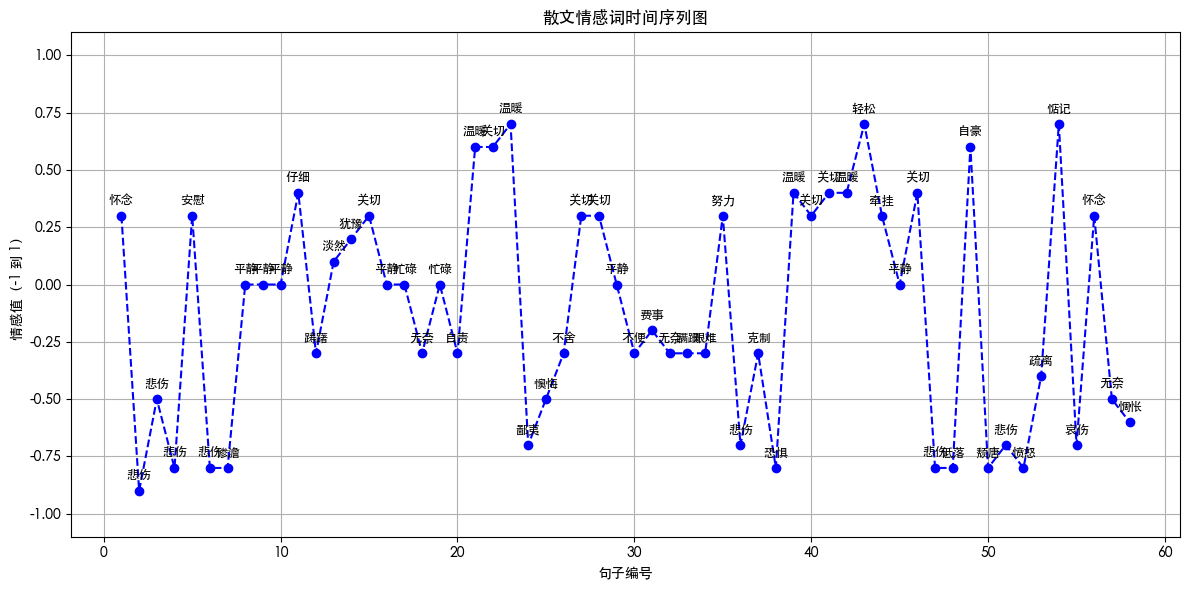

In [6]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 设置中文字体（适配不同系统）
#plt.rcParams['font.family'] = 'SimHei'  # 黑体，适用于 Windows
plt.rcParams['font.family'] = 'Heiti TC ' #mac对应的黑体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号 '-' 显示为方块的问题

# 如果你使用的是 macOS，可换为：
# plt.rcParams['font.family'] = 'Heiti TC'

# 如果是 Linux（如 Ubuntu）且安装了中文字体：
# plt.rcParams['font.family'] = 'Noto Sans CJK SC'

# 画图
x = [item[0] for item in emotion_results]
y = [item[3] for item in emotion_results]
labels = [item[2] for item in emotion_results]

plt.figure(figsize=(12, 6))
plt.plot(x, y, linestyle='--', marker='o', color='blue')

# 添加每个点的中文情感词标签
for i in range(len(x)):
    plt.text(x[i], y[i] + 0.05, labels[i], ha='center', fontsize=9)

plt.title("散文情感词时间序列图")
plt.xlabel("句子编号")
plt.ylabel("情感值（-1 到 1）")
plt.ylim(-1.1, 1.1)
plt.grid(True)
plt.tight_layout()
plt.show()


共 58 句，得分均值 -0.114
最低三句： [(2, '悲伤', -0.9), (4, '悲伤', -0.8), (6, '悲伤', -0.8)]
最高三句： [(23, '温暖', 0.7), (43, '轻松', 0.7), (54, '惦记', 0.7)]


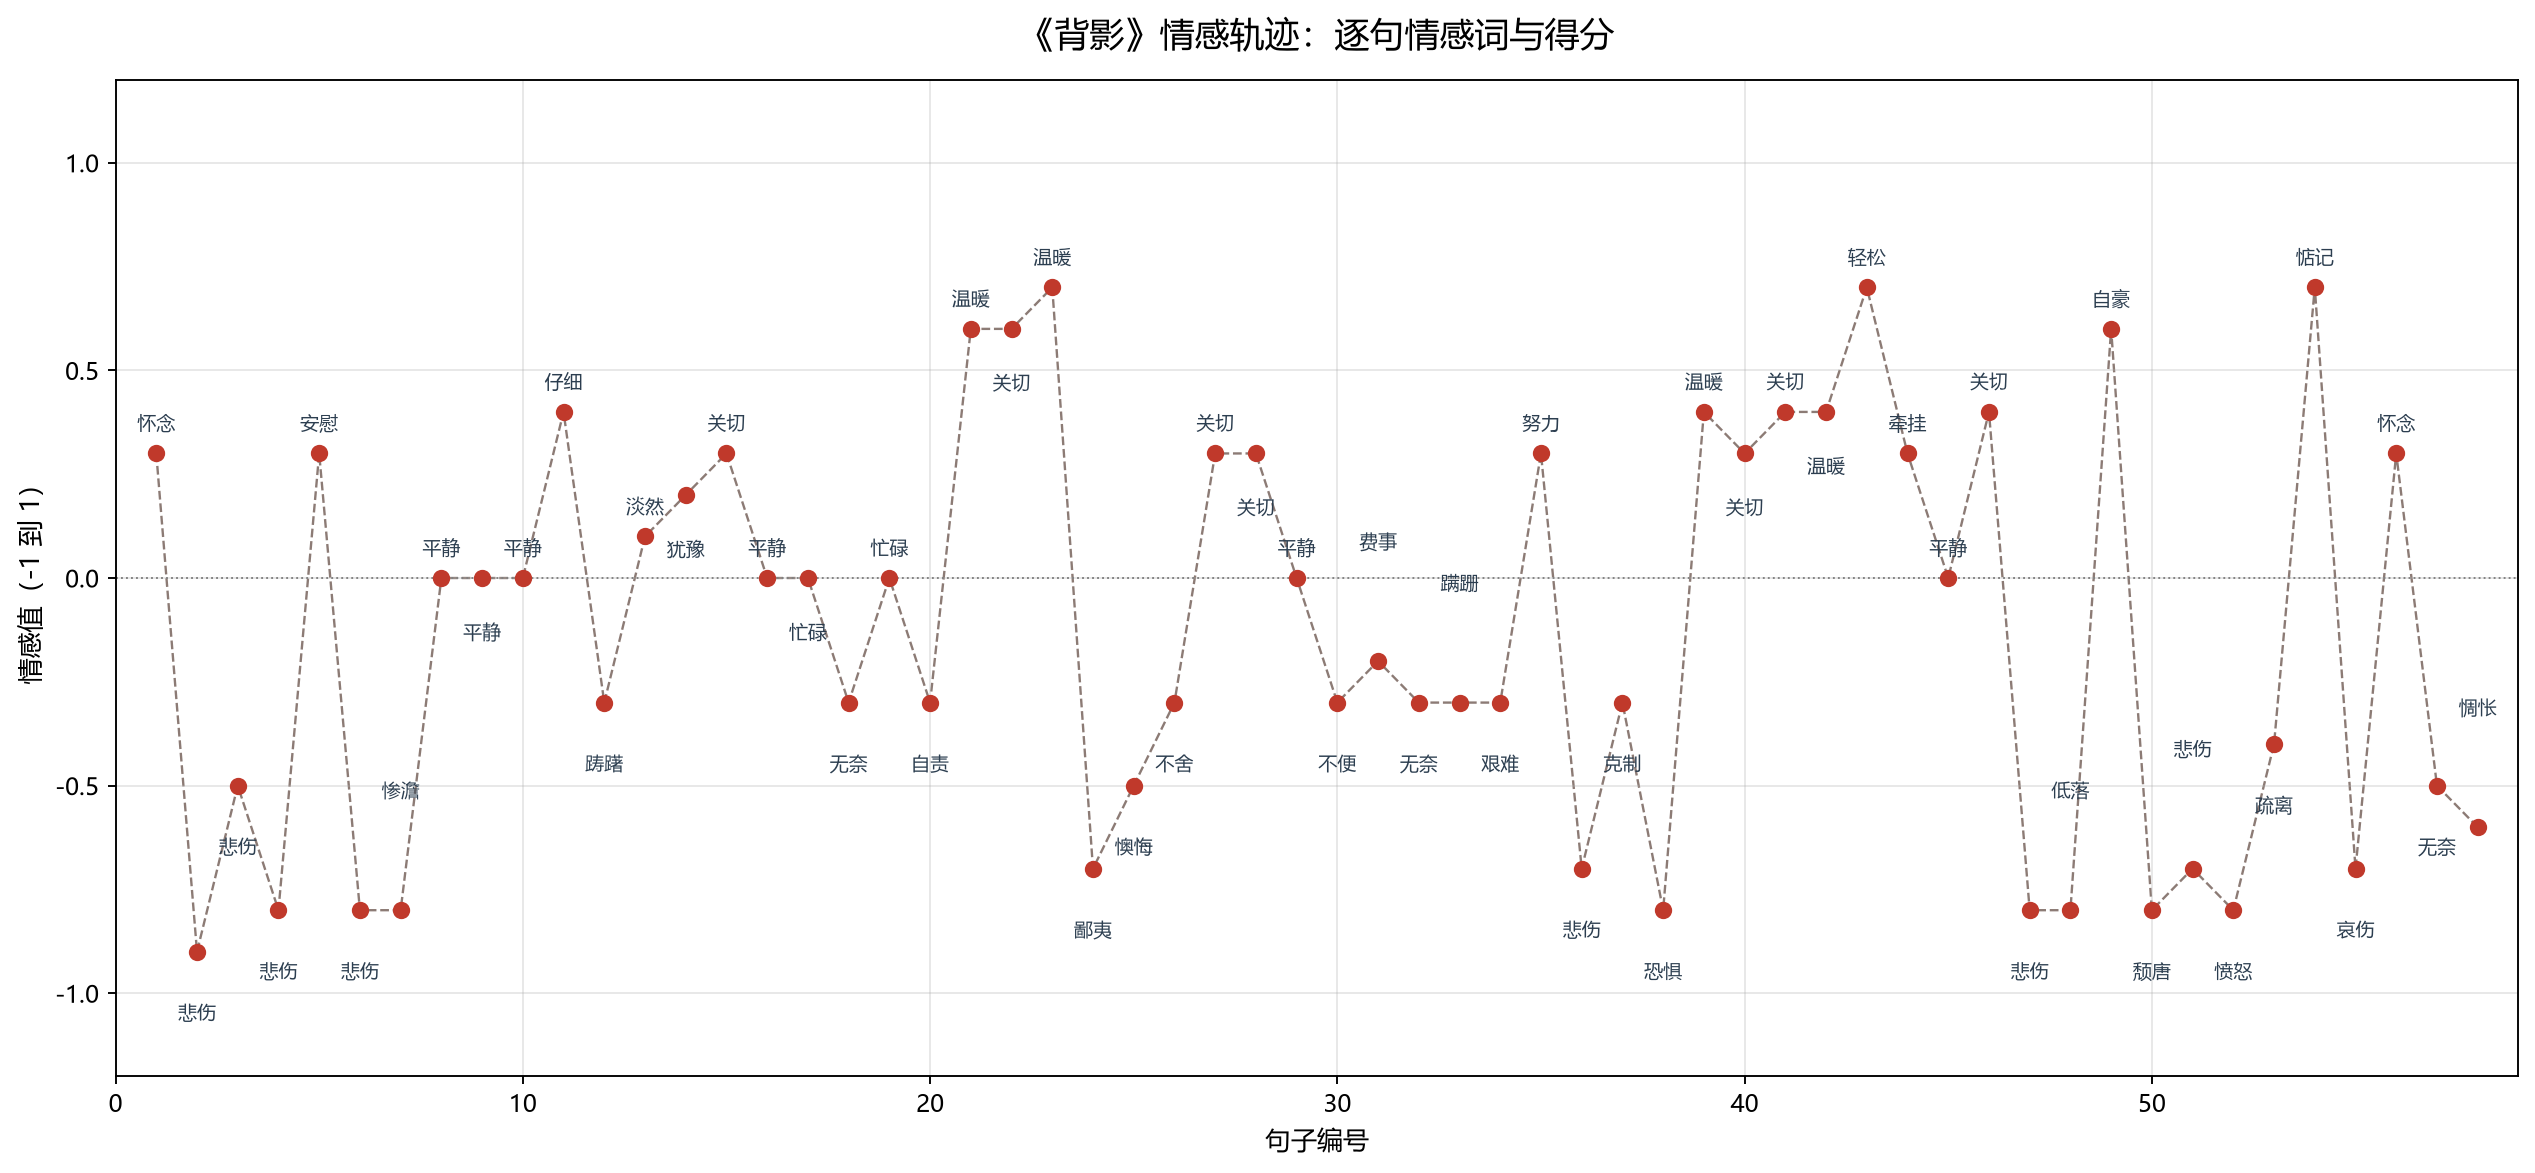

In [8]:
# 上一格把字体设成了 'Heiti TC '，那是 macOS 的字体，在 Windows 上画出来全是方块。
# 这里把上一步已经跑出来的真实结果固定下来，换微软雅黑重画，不再重复调用 API。
import matplotlib.pyplot as plt

emotion_results = [
    (1, "怀念", 0.3),
    (2, "悲伤", -0.9),
    (3, "悲伤", -0.5),
    (4, "悲伤", -0.8),
    (5, "安慰", 0.3),
    (6, "悲伤", -0.8),
    (7, "惨澹", -0.8),
    (8, "平静", 0.0),
    (9, "平静", 0.0),
    (10, "平静", 0.0),
    (11, "仔细", 0.4),
    (12, "踌躇", -0.3),
    (13, "淡然", 0.1),
    (14, "犹豫", 0.2),
    (15, "关切", 0.3),
    (16, "平静", 0.0),
    (17, "忙碌", 0.0),
    (18, "无奈", -0.3),
    (19, "忙碌", 0.0),
    (20, "自责", -0.3),
    (21, "温暖", 0.6),
    (22, "关切", 0.6),
    (23, "温暖", 0.7),
    (24, "鄙夷", -0.7),
    (25, "懊悔", -0.5),
    (26, "不舍", -0.3),
    (27, "关切", 0.3),
    (28, "关切", 0.3),
    (29, "平静", 0.0),
    (30, "不便", -0.3),
    (31, "费事", -0.2),
    (32, "无奈", -0.3),
    (33, "蹒跚", -0.3),
    (34, "艰难", -0.3),
    (35, "努力", 0.3),
    (36, "悲伤", -0.7),
    (37, "克制", -0.3),
    (38, "恐惧", -0.8),
    (39, "温暖", 0.4),
    (40, "关切", 0.3),
    (41, "关切", 0.4),
    (42, "温暖", 0.4),
    (43, "轻松", 0.7),
    (44, "牵挂", 0.3),
    (45, "平静", 0.0),
    (46, "关切", 0.4),
    (47, "悲伤", -0.8),
    (48, "低落", -0.8),
    (49, "自豪", 0.6),
    (50, "颓唐", -0.8),
    (51, "悲伤", -0.7),
    (52, "愤怒", -0.8),
    (53, "疏离", -0.4),
    (54, "惦记", 0.7),
    (55, "哀伤", -0.7),
    (56, "怀念", 0.3),
    (57, "无奈", -0.5),
    (58, "惆怅", -0.6)
]

plt.rcParams['font.family'] = ['Microsoft YaHei', 'SimHei', 'SimSun']
plt.rcParams['axes.unicode_minus'] = False

x = [r[0] for r in emotion_results]
y = [r[2] for r in emotion_results]
labels = [r[1] for r in emotion_results]

# 相邻两句情感值接近时，标签会叠在一起。这里交替上下错开
offsets, prev_x, prev_y, flip = [], None, None, False
for xi, yi in zip(x, y):
    if prev_x is not None and xi - prev_x <= 2 and abs(yi - prev_y) < 0.16:
        flip = not flip
    else:
        flip = False
    base = 0.07 if yi >= 0 else -0.15
    offsets.append(-base * 1.9 if flip else base)
    prev_x, prev_y = xi, yi

plt.figure(figsize=(15, 7))
plt.axhline(0, color="gray", linewidth=0.8, linestyle=":")
plt.plot(x, y, linestyle="--", linewidth=1, color="#8c7b75", zorder=1)
plt.scatter(x, y, s=40, color="#c0392b", zorder=2)

for xi, yi, lb, off in zip(x, y, labels, offsets):
    plt.text(xi, yi + off, lb, ha="center", va="center",
             fontsize=8, color="#2c3e50")

plt.title("《背影》情感轨迹：逐句情感词与得分", fontsize=15, pad=14)
plt.xlabel("句子编号", fontsize=11)
plt.ylabel("情感值（-1 到 1）", fontsize=11)
plt.ylim(-1.2, 1.2)
plt.xlim(0, len(x) + 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("beijing_sentiment_timeline.png", dpi=170, bbox_inches="tight")
plt.show()

print(f"共 {len(emotion_results)} 句，得分均值 {sum(y)/len(y):.3f}")
print("最低三句：", sorted(emotion_results, key=lambda r: r[2])[:3])
print("最高三句：", sorted(emotion_results, key=lambda r: -r[2])[:3])

### 这张图在说什么

横轴是句子序号，纵轴是情感值，虚线把相邻句子的情绪连起来——**散文的情感不是一条直线，而是一条被事件顶起来的折线**。

三个明显的高点，都落在"父亲为我做了什么"的位置：第 21 到 23 句，父亲爬月台买橘子那一段，"温暖"0.6、"关切"0.6、"温暖"0.7，连续三句都在 0.6 以上。这是全文唯一一段情绪持续向上的区间，也是被选进课本的那一段，情感强度和文学价值在这张图上恰好对上了。

低谷有两处。第一处是开头第 2 到 7 句，"悲伤"反复出现，-0.9、-0.8 连续拉低——祖母去世、父亲失业、变卖典质，这几句是纯粹的家境描写，情绪是压着的。第二处在第 47 句往后，父亲来信说"大约大去之期不远矣"：47、48 两句先跌到 -0.8，中间 49 句"自豪"+0.6、54 句"惦记"+0.7 有两次短暂抬头，其余句子基本都压在 -0.4 以下，收在"惆怅"-0.6。整篇文章的情感曲线，是**先抑、中扬、后抑更深**。

有两个中段值得单说。第 24 句"鄙夷"是全文唯一的负向转折藏在暖色区里——那是我当时嫌父亲说话不漂亮、非要自己插嘴的心理，一种年轻时的自以为是；紧接着第 25 句"懊悔"，一正一反紧挨着，正好是那句"我那时真是聪明过分"的自我审判。第 43 句"轻松"出现在父亲背影混入人群、我坐下再找不着他的时候，这个 0.7 的高分其实读反了——那不是轻松，是失去了要照看的对象之后的一瞬间的、带着惶恐的空。

这张图也暴露了方法本身的三个问题，值得记下来：

1. **每句只取一个情感词，粒度太粗。** 一句话里常常同时有叙事和情绪，第 5 句父亲说"事已如此，不必难过"，模型把它判成"安慰 +0.3"，可这句话在上下文里是压抑的前奏，不是真的乐观。
2. **"平静 0.0"出现了 6 次，另有 2 处"忙碌"也是 0.0，全文零点共 8 个。** 大多集中在父亲忙于讲价、照看行李那些纯动作描写上。模型对没有明显情绪词的句子一律给 0，这些点其实不是"中性"，而是"模型没读到"，两者不该混为一谈。
3. **句子切分有瑕疵。** 第 5、6 句和第 15、16 句是被引号里的感叹号切开的，`"` 自己单独成了一句，所以编号 6 和 16 的内容落在下一句上。这就是程序开头那句 `re.split(r'(?<=[。！])')` 的代价：按标点切，不管引号是否闭合。

所以这份结果的正确用法，不是"看总分判断文章悲不悲"，而是**拿它定位值得细读的句子**。图上一眼能看出情绪的峰谷在哪几句，人再去读那几句——情感分析在这里做的是索引，不是结论。